In [1]:
import random
import matplotlib.pyplot as plt
import pandas as pd
import math
from scipy import stats



# Geometric Brownian Motion Simulation

$$S_T=S_0e^{(r-\frac12\sigma^2)T+\sigma\sqrt{T}Z}$$
Where:
- $S_0$: current stock price.
- $S_T$: simulated stock price at expiration.
- $r$: annual risk-free interest rate.
- $\sigma$: annual volatility.
- $T$: time to expiration in years.
- $Z$: random number drawn from a standard normal distribution.
- $e$: exponential function.


In [2]:
s0 = 100
r = 0.05
sigma = 0.35
T = 1
step = 100
num_sim = 25

In [3]:
def GBM(s0, r, sigma, dt):
  Z = random.normalvariate(mu = 0.0, sigma = 1.0)
  S = s0 * math.exp((r - 0.5 * (sigma**2)) * dt + sigma * math.sqrt(dt) * Z)
  return S

def simulate(s0, r, sigma, T, step, num_sim):
    deltaT = T / step
    roadmap = []

    for sim in range(num_sim):
        current = [s0]
        S = s0

        for i in range(step):
            S = GBM(S, r, sigma, deltaT)
            current.append(S)

        roadmap.append(current)

    return roadmap

In [4]:
plotting = simulate(s0, r, sigma, T, step, num_sim)

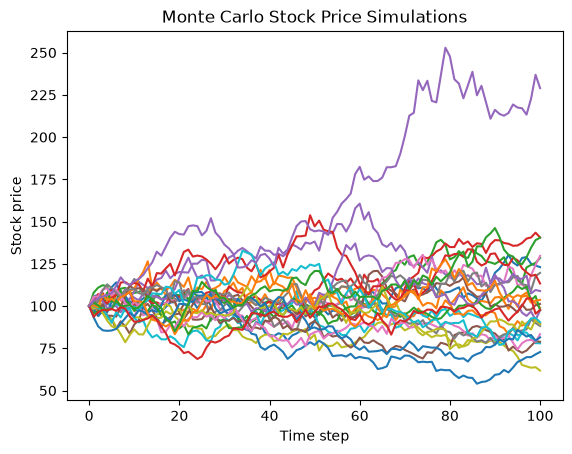

In [5]:
for path in plotting:
    plt.plot(path)

plt.xlabel("Time step")
plt.ylabel("Stock price")
plt.title("Monte Carlo Stock Price Simulations")
plt.show()


# Black-Scholes Option Pricing Model

## 1. Stock Price Parameters

- S0 = Current stock price
- K = Strike price (exercise price)
- T = Time to expiration (in years)
- r = Annual risk-free interest rate
- σ (sigma) = Annualized volatility of the stock
- N(x) = Cumulative standard normal distribution function
- e = Euler's number (exponential function)

## 2. Black-Scholes Variables

**Calculate d1:**

$$
d_1 = \frac{\ln(S_0/K) + (r + \frac{\sigma^2}{2})T}
{\sigma\sqrt{T}}
$$

**Calculate d2:**

$$
d_2 = d_1 - \sigma\sqrt{T}
$$

## 3. European Call Option Price

$$
C = S_0N(d_1) - Ke^{-rT}N(d_2)
$$

## 4. European Put Option Price

$$
P = Ke^{-rT}N(-d_2) - S_0N(-d_1)
$$

## 5. Important Notes

- C = Theoretical price of a European call option.
- P = Theoretical price of a European put option.
- N(d1) and N(d2) = Cumulative probabilities from the standard normal distribution.
- e^(-rT) = Discount factor used to convert future value into present value.
- The model assumes constant volatility and a constant risk-free interest rate.
- The standard formulas assume no dividends and European-style exercise.


In [6]:
s0 = 100
r = 0.05
sigma = 0.35
T = 1
step = 50
num_sim = 5000

In [7]:
def European_Call(s0, K, T, r, sigma):
    d1 = (math.log(s0 / K) + (r + (sigma ** 2) / 2) * T) / (sigma * math.sqrt(T))
    d2 = d1 - sigma * math.sqrt(T)

    C = s0 * stats.norm.cdf(d1) - K * math.exp(-r * T) * stats.norm.cdf(d2)

    return C

def European_Put(s0, K, T, r, sigma):
    d1 = (math.log(s0 / K) + (r + (sigma ** 2) / 2) * T) / (sigma * math.sqrt(T))
    d2 = d1 - sigma * math.sqrt(T)
    
    C = K * math.exp(-r * T) * stats.norm.cdf(-d2) - s0 * stats.norm.cdf(-d1)
    return C


In [8]:
# At-the-money
atm = European_Call(s0, 100, T, r, sigma)

# In-the-money
itm = European_Call(s0, 80, T, r, sigma)

# Out-of-the-money
otm = European_Call(s0, 120, T, r, sigma)

print("ATM:", atm)
print("ITM:", itm)
print("OTM:", otm)

ATM: 16.12842888157588
ITM: 27.666374067323147
OTM: 8.838933853756686


In [9]:
# At-the-money
atm = European_Put(s0, 100, T, r, sigma)

# In-the-money
itm = European_Put(s0, 1000, T, r, sigma)

# Out-of-the-money
otm = European_Put(s0, 98, T, r, sigma)

print("ATM:", atm)
print("ITM:", itm)
print("OTM:", otm)

ATM: 11.251371331647292
ITM: 851.229424501684
OTM: 10.297577681424286


In [10]:
def Monte_Carlo_Pricing_Call(K, T, r, simplot):

  # Store simulated payoffs
  payoffs = []

  # Go through every simulated path
  for path in simplot:
      # Get the final stock price
      ST = path[-1]

      # Calculate the call option payoff
      payoff = max(ST - K, 0)

      payoffs.append(payoff)

  # Calculate Monte Carlo option price
  # e^{r * T} = continous compounding

  MC_price = math.exp(-r * T) * (sum(payoffs) / len(payoffs))
  print("Monte Carlo Price: ", MC_price)

  return MC_price

def Monte_Carlo_Pricing_Put(K, T, r, simplot):

  # Store simulated payoffs
  payoffs = []

  # Go through every simulated path
  for path in simplot:
      # Get the final stock price
      ST = path[-1]

      # Calculate the put option payoff
      payoff = max(K - ST, 0)

      payoffs.append(payoff)

  # Calculate Monte Carlo option price
  # e^{r * T} = continous compounding

  MC_price = math.exp(-r * T) * (sum(payoffs) / len(payoffs))
  print("Monte Carlo Price: ", MC_price)

  return MC_price

def Black_Scholes_Pricing_Call(s0, K, T, r, sigma):
  pricing = European_Call(s0, K, T, r, sigma)

  print("Black-Scholes Price: ", pricing)
  return pricing

def Black_Scholes_Pricing_Put(s0, K, T, r, sigma):
  pricing = European_Put(s0, K, T, r, sigma)

  print("Black-Scholes Price: ", pricing)
  return pricing

In [11]:
def compare_call(s0, K, T, r, sigma, step, num_sim):
    simplot = simulate(s0, r, sigma, T, step, num_sim)
    for path in simplot:
        plt.plot(path)

    plt.xlabel("Time step")
    plt.ylabel("Stock price")
    plt.title("Monte Carlo Calling Stock Price Simulations")
    plt.show()
    print()

    x = Monte_Carlo_Pricing_Call(K, T, r, simplot)
    y = Black_Scholes_Pricing_Call(s0, K, T, r, sigma)

    print("Difference: ", abs(x - y))

def compare_put(s0, K, T, r, sigma, step, num_sim):
    simplot = simulate(s0, r, sigma, T, step, num_sim)
    for path in simplot:
        plt.plot(path)

    plt.xlabel("Time step")
    plt.ylabel("Stock price")
    plt.title("Monte Carlo Putting Stock Price Simulations")
    plt.show()
    print()

    x = Monte_Carlo_Pricing_Put(K, T, r, simplot)
    y = Black_Scholes_Pricing_Put(s0, K, T, r, sigma)

    print("Difference: ", abs(x - y))

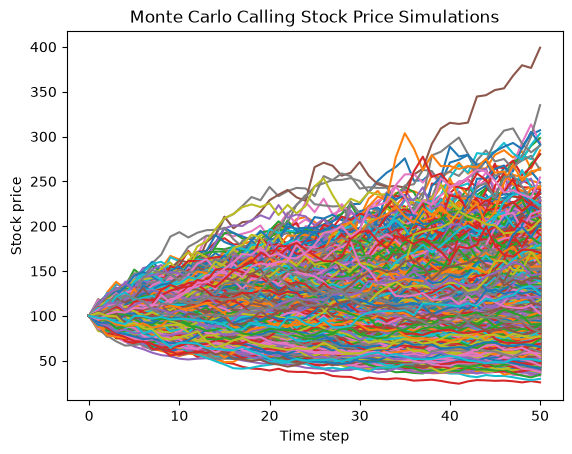


Monte Carlo Price:  0.6083979755774958
Black-Scholes Price:  0.619308759392819
Difference:  0.010910783815323288


In [12]:
compare_call(s0, 200, T, r, sigma, step, num_sim)

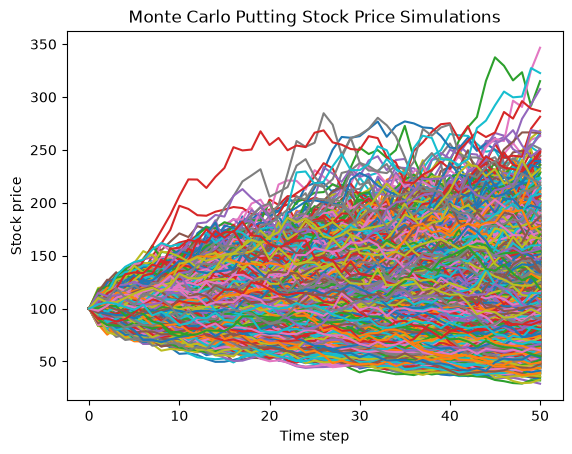


Monte Carlo Price:  90.54317281231054
Black-Scholes Price:  90.86519365953563
Difference:  0.3220208472250903


In [13]:
compare_put(s0, 200, T, r, sigma, step, num_sim)